# NetZeroAI - Exploratory Data Analysis

Run from the project root or from `notebook/`. Covers: why the originally attached `global_warming_dataset.csv` was rejected, the real OWID CO2/Energy data used instead, the reference-year choice, missing data and regional imputation, and the indicator distributions that motivate percentile normalization.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import constants as C

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 1. Why the synthetic dataset was rejected

`global_warming_dataset.csv` is 100k rows of `Country_1`..`Country_195` synthetic labels. Row-level correlations are all ~0 (max |r| ~0.01), and stay at chance level after grouping by country. The file has since been removed from disk, so this cell recomputes the audit if it is present and otherwise shows the saved heatmap from the original audit.

global_warming_dataset.csv is no longer on disk - showing the saved audit heatmap.


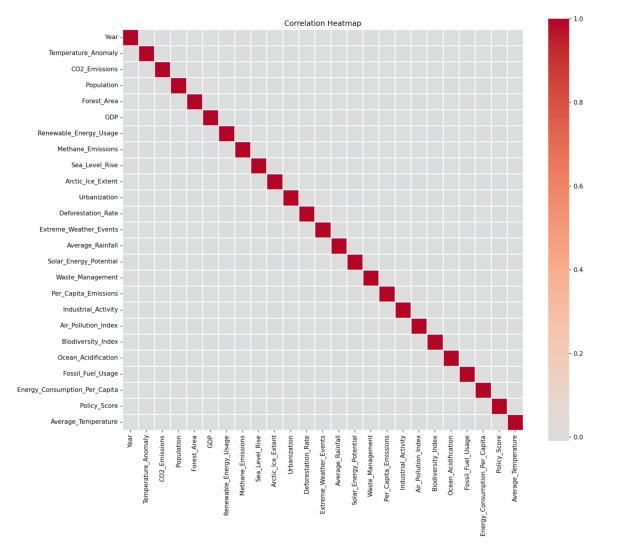

In [2]:
synthetic_path = ROOT / "global_warming_dataset.csv"
if synthetic_path.exists():
    synthetic = pd.read_csv(synthetic_path)
    num_cols = synthetic.select_dtypes(include="number").columns.drop("Year")
    corr = synthetic[num_cols].corr()
    np.fill_diagonal(corr.values, np.nan)
    print("Max |correlation| (row-level):", np.nanmax(np.abs(corr.values)))
else:
    print("global_warming_dataset.csv is no longer on disk - showing the saved audit heatmap.")
    img = plt.imread(ROOT / "reports" / "assets" / "synthetic_correlation.png")
    plt.figure(figsize=(8, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## 2. Raw OWID data and the reference year

The index uses a single cross-sectional year. 2022 is the latest year with GDP data - 2023 onwards has none in either file.

In [3]:
co2 = pd.read_csv(C.RAW_CO2_PATH)
energy = pd.read_csv(C.RAW_ENERGY_PATH)
print(f"CO2 file: {co2.shape}, years {co2.year.min()}-{co2.year.max()}")
print(f"Energy file: {energy.shape}, years {energy.year.min()}-{energy.year.max()}")
pd.DataFrame({
    "co2 file: rows with GDP": co2.groupby("year")["gdp"].count(),
    "energy file: rows with GDP": energy.groupby("year")["gdp"].count(),
}).loc[2018:2024]

CO2 file: (50411, 79), years 1750-2024
Energy file: (23377, 130), years 1900-2025


,co2 file: rows with GDP,energy file: rows with GDP
year,,
2018,165.0,166.0
2019,165.0,166.0
2020,165.0,166.0
2021,165.0,166.0
2022,165.0,166.0
2023,0.0,0.0
2024,0.0,0.0


In [4]:
is_real = co2["iso_code"].astype(str).str.match(C.REAL_ISO_REGEX) & ~co2["iso_code"].isin(C.EXCLUDE_ISO)
print("Distinct 'country' labels in the CO2 file:", co2["country"].nunique())
print("...of which real ISO-3 countries/territories:", co2.loc[is_real, "country"].nunique())
print("Examples of excluded aggregates:", sorted(co2.loc[~is_real, "country"].unique())[:12])

Distinct 'country' labels in the CO2 file: 254
...of which real ISO-3 countries/territories: 217
Examples of excluded aggregates: ['Africa', 'Africa (GCP)', 'Antarctica', 'Asia', 'Asia (GCP)', 'Asia (excl. China and India)', 'Central America (GCP)', 'Europe', 'Europe (GCP)', 'Europe (excl. EU-27)', 'Europe (excl. EU-28)', 'European Union (27)']


## 3. Building the analysis table

`DataIngestion` filters to real countries, merges the two files at 2022, computes the 2013-2022 CO2-per-capita trend slope, drops countries missing more than one of the five indicators, and imputes the rest from UN M49 regional medians.

In [5]:
from src.components.data_ingestion import DataIngestion

train_path, test_path = DataIngestion().initiate_data_ingestion()
merged = pd.read_csv(C.DATA_PATH)
df = pd.read_csv(train_path)
indicators = list(C.INDICATOR_DIRECTIONS)
print(f"Merged at {C.REFERENCE_YEAR}: {len(merged)} countries -> analysis table: {len(df)} countries")
print("Dropped:", sorted(set(merged.country) - set(df.country)))
merged[indicators].isna().sum().rename("missing in the 205-country merge").to_frame()

Merged at 2022: 205 countries -> analysis table: 194 countries
Dropped: ['Bermuda', 'Curacao', 'Faroe Islands', 'French Polynesia', 'Greenland', 'Micronesia (country)', 'Montserrat', 'New Caledonia', 'Niue', 'Saint Pierre and Miquelon', 'Tuvalu']


,missing in the 205-country merge
co2_per_capita,0
ghg_per_capita,9
co2pc_trend_slope,0
renewables_share_elec,4
gdp_per_capita,41


In [6]:
imputed = [
    {"country": r.country, "indicator": col, "imputed value": round(r[col], 2), "source": r[f"{col}_impute_source"]}
    for col in indicators for _, r in df[df[f"{col}_imputed"]].iterrows()
]
pd.DataFrame(imputed)

,country,indicator,imputed value,source
0,Palestine,ghg_per_capita,7.02,Western Asia median (n=17)
1,Antigua and Barbuda,gdp_per_capita,9940.92,Caribbean median (n=8)
2,Aruba,gdp_per_capita,9940.92,Caribbean median (n=8)
3,Bahamas,gdp_per_capita,9940.92,Caribbean median (n=8)
4,Belize,gdp_per_capita,9437.57,Central America median (n=7)
5,Bhutan,gdp_per_capita,5411.70,Southern Asia median (n=7)
6,British Virgin Islands,gdp_per_capita,9940.92,Caribbean median (n=8)
7,Brunei,gdp_per_capita,8904.64,South-eastern Asia median (n=9)
8,Cook Islands,gdp_per_capita,12605.77,global median (n=164)
9,East Timor,gdp_per_capita,8904.64,South-eastern Asia median (n=9)


Imputation uses the median of the most specific UN M49 group with at least `MIN_IMPUTATION_GROUP_OBS` observed values. The Pacific sub-regions (Melanesia, Micronesia, Polynesia) have no observed GDP at all, and their parent region Oceania only has Australia and New Zealand, so they fall back to the global median rather than inheriting Australian incomes.

## 4. Indicator distributions

In [7]:
df[indicators].describe().T.assign(skew=df[indicators].skew())

,count,mean,std,min,25%,50%,75%,max,skew
co2_per_capita,194.0,4.404552,5.490862,0.058000,0.810500,2.749500,5.662000,37.890000,2.803065
ghg_per_capita,194.0,7.123820,7.006119,0.697000,2.697750,5.269000,8.758250,45.805000,2.620540
co2pc_trend_slope,194.0,-0.036528,0.177902,-1.019430,-0.066115,0.001594,0.028414,0.980055,-1.264080
renewables_share_elec,194.0,37.532526,32.278192,0.000000,9.823500,27.719500,63.958750,100.000000,0.618842
gdp_per_capita,194.0,17809.621446,18849.740459,688.912784,4781.992952,12021.931370,25331.384138,131990.525389,2.238399


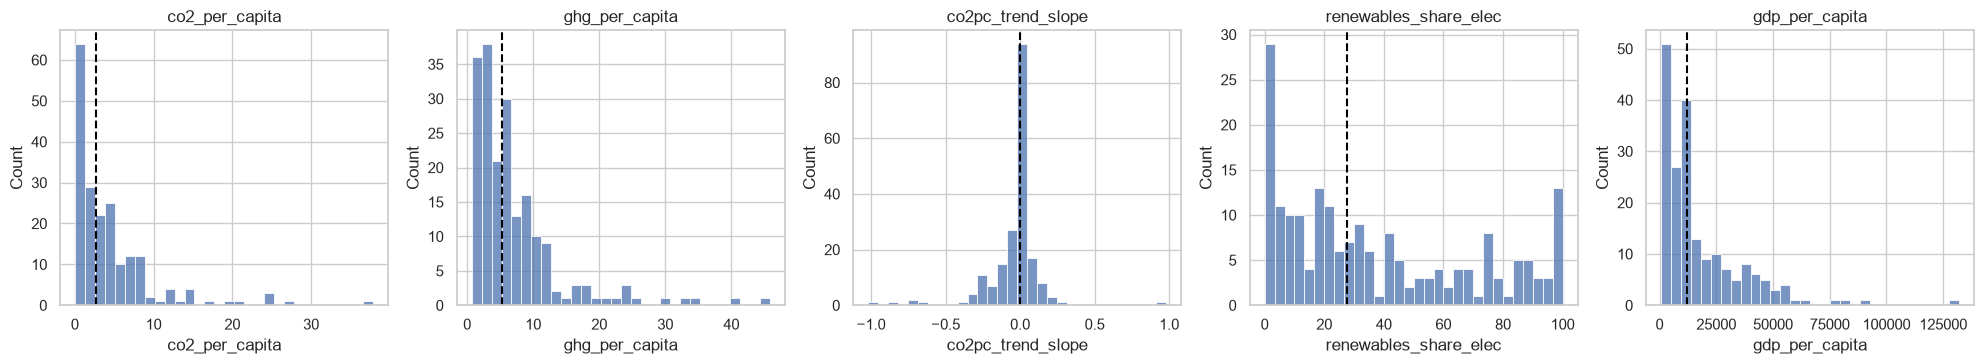

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, col in zip(axes, indicators):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.axvline(df[col].median(), color="black", linestyle="--")
    ax.set_title(col)
plt.tight_layout()
plt.show()

CO2 and GHG per capita and GDP per capita are strongly right-skewed (a few petro-states and high-income microstates sit far out in the tail). Min-max scaling would let those outliers compress everyone else into a narrow band, which is why the index uses percentile ranks.

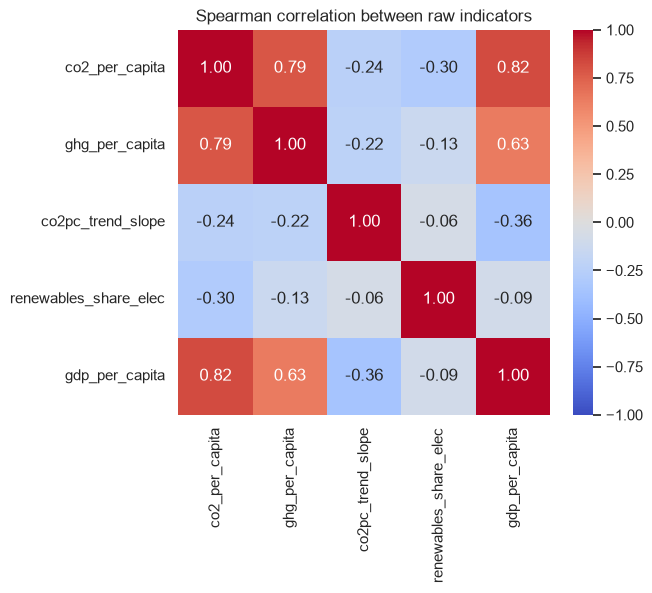

In [9]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[indicators].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation between raw indicators")
plt.show()

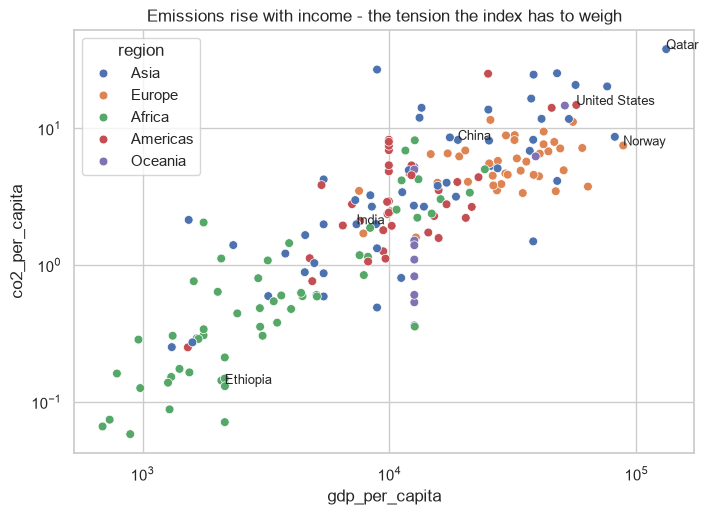

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="gdp_per_capita", y="co2_per_capita",
                hue="region", ax=ax, s=40)
ax.set(xscale="log", yscale="log", title="Emissions rise with income - the tension the index has to weigh")
for name in ["Qatar", "India", "Norway", "Ethiopia", "United States", "China"]:
    r = df[df.country == name].iloc[0]
    ax.annotate(name, (r.gdp_per_capita, r.co2_per_capita), fontsize=9)
plt.show()